# JS11 – Klasifikasi 2: Praktikum 5
## Klasifikasi Citra Siang dan Malam

**Tujuan praktikum**

1. Membaca dan memvisualisasikan dataset citra siang dan malam.
2. Melakukan standardisasi ukuran gambar dan encoding label.
3. Mengekstrak fitur sederhana berupa **rata-rata kecerahan** dari ruang warna HSV.
4. Membangun classifier threshold sederhana.
5. Membandingkan threshold dengan SVM kernel RBF.
6. Menganalisis pengaruh pemilihan threshold terhadap akurasi.

**Tentang data:** Dataset berisi citra siang (`day`) dan malam (`night`) yang sudah dipisahkan ke folder `training` dan `test`.

- Training: 120 day + 120 night = 240 gambar.
- Test: 80 day + 80 night = 160 gambar.

Setiap gambar distandarkan ke ukuran **1100 × 600 piksel**. Fitur yang digunakan pada praktikum ini adalah rata-rata kanal **V (Value)** dari ruang warna HSV, yang merepresentasikan kecerahan.

### 0. Import library

In [1]:
import platform
import random
from pathlib import Path

import cv2
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.svm import SVC

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("OpenCV  :", cv2.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
OpenCV  : 5.0.0
seaborn : 0.13.2


### 1. Memuat daftar gambar

Fungsi `load_dataset` mengembalikan daftar pasangan `(path, label)` agar gambar tidak semuanya dimuat ke memori sekaligus. Gambar hanya dibaca saat dibutuhkan.

In [2]:
def load_dataset(img_dir):
    p = Path(img_dir)
    items = []

    for folder in sorted(p.iterdir()):
        if folder.is_dir():
            label = folder.name
            for file in sorted(folder.glob("*.jpg")):
                items.append((file, label))

    return items


train_img = load_dataset("images/training")
test_img = load_dataset("images/test")

print("Jumlah gambar training:", len(train_img))
print("Jumlah gambar test    :", len(test_img))

from collections import Counter
print("Distribusi training   :", Counter(label for _, label in train_img))
print("Distribusi test       :", Counter(label for _, label in test_img))

Jumlah gambar training: 240
Jumlah gambar test    : 160
Distribusi training   : Counter({'day': 120, 'night': 120})
Distribusi test       : Counter({'day': 80, 'night': 80})


### 2. Visualisasi contoh gambar

Path  : images/training/day/20151103_161128.jpg
Shape : (600, 1100, 3)
Label : day


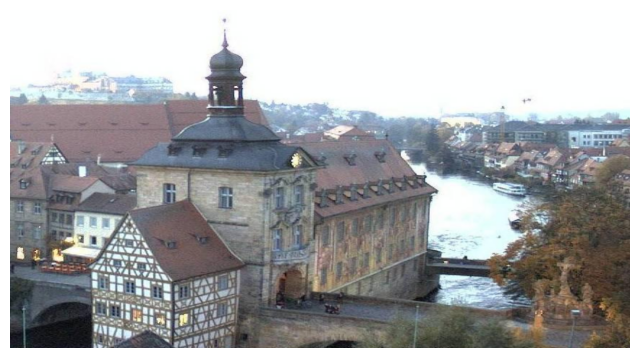

In [3]:
def load_image(path, size=(1100, 600)):
    img = mpimg.imread(path)

    if img.ndim == 3 and img.shape[2] == 4:
        img = img[:, :, :3]

    if img.dtype != np.uint8:
        if img.max() <= 1.0:
            img = (img * 255).astype(np.uint8)
        else:
            img = img.astype(np.uint8)

    return cv2.resize(img, size)


def random_img_viz(img_list):
    idx = np.random.randint(0, len(img_list))
    path, label = img_list[idx]
    img = load_image(path)

    plt.imshow(img)
    print(f"Path  : {path}")
    print(f"Shape : {img.shape}")
    print(f"Label : {label}")
    plt.axis("off")
    plt.show()


random_img_viz(train_img)

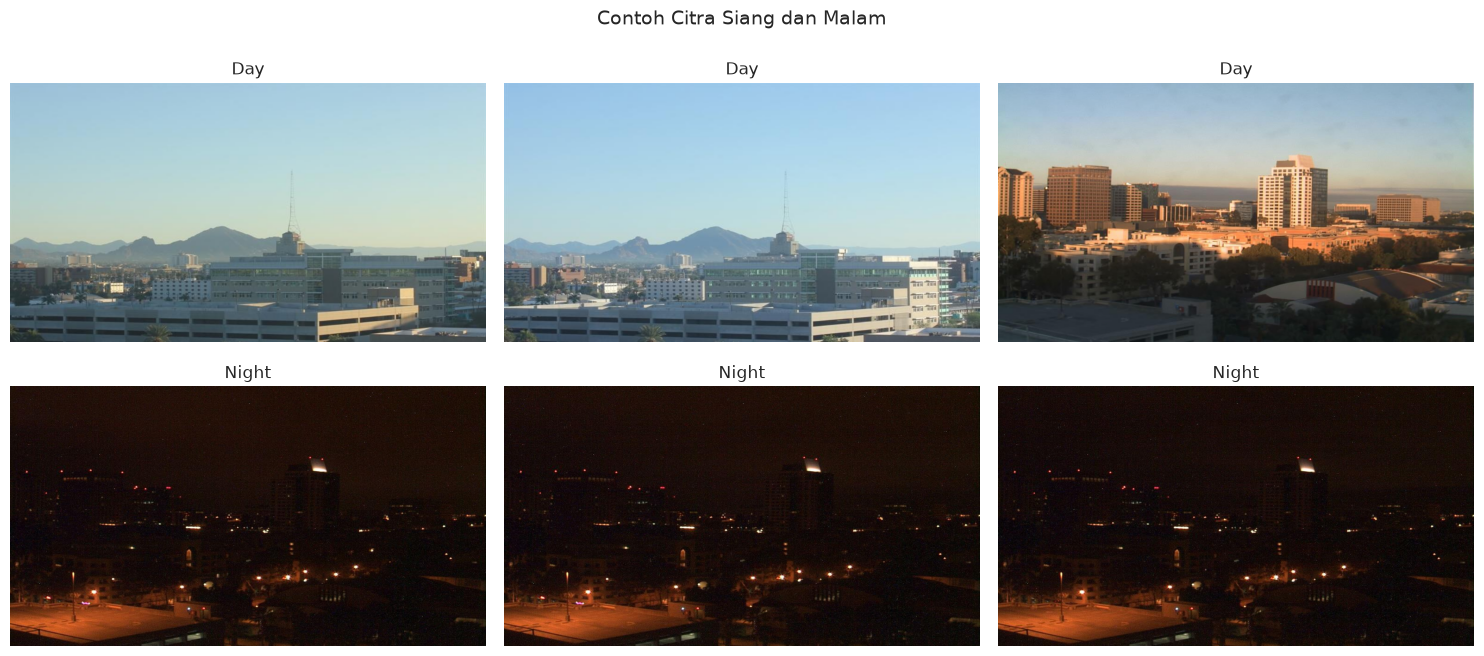

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

day_paths = [p for p, label in train_img if label == "day"][:3]
night_paths = [p for p, label in train_img if label == "night"][:3]

for ax, path in zip(axes[0], day_paths):
    ax.imshow(load_image(path))
    ax.set_title("Day")
    ax.axis("off")

for ax, path in zip(axes[1], night_paths):
    ax.imshow(load_image(path))
    ax.set_title("Night")
    ax.axis("off")

plt.suptitle("Contoh Citra Siang dan Malam", size=14)
plt.tight_layout()
plt.show()

### 3. Pra pengolahan dan ekstraksi fitur kecerahan

Label diubah menjadi angka: `day = 1`, `night = 0`.

Fungsi `avg_brightness` mengubah gambar RGB ke HSV, lalu menghitung rata-rata kanal V. Nilai V berada pada rentang 0–255 karena gambar dibaca sebagai `uint8`.

In [5]:
def label_encoder(label):
    return 1 if label == "day" else 0


def avg_brightness(image):
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    return sum_brightness / area


def extract_brightness(img_list):
    rows = []
    for path, label in img_list:
        img = load_image(path)
        rows.append({
            "path": str(path),
            "label": label,
            "label_num": label_encoder(label),
            "brightness": avg_brightness(img),
        })
    return pd.DataFrame(rows)

Shape gambar : (600, 1100, 3)
Tipe data    : uint8
Rata-rata kecerahan: 175.09


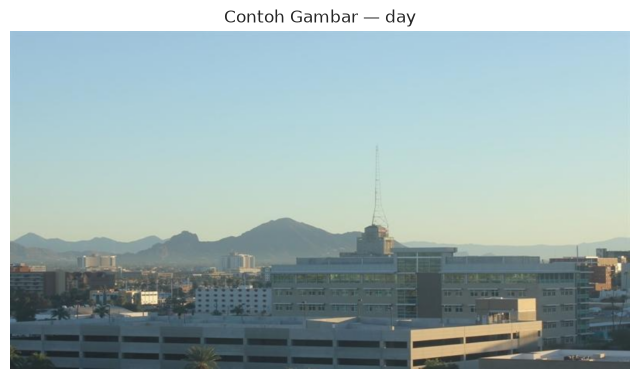

In [6]:
sample_path = train_img[0][0]
sample_img = load_image(sample_path)

print("Shape gambar :", sample_img.shape)
print("Tipe data    :", sample_img.dtype)
print(f"Rata-rata kecerahan: {avg_brightness(sample_img):.2f}")

plt.imshow(sample_img)
plt.title(f"Contoh Gambar — {train_img[0][1]}")
plt.axis("off")
plt.show()

### 4. Ekstraksi fitur untuk seluruh data

In [7]:
train_df = extract_brightness(train_img)
test_df = extract_brightness(test_img)

print("Train:", train_df.shape)
print("Test :", test_df.shape)
train_df.head()

Train: (240, 4)
Test : (160, 4)


,path,label,label_num,brightness
0,images/training/day/20151101_142050.jpg,day,1,175.092992
1,images/training/day/20151101_145049.jpg,day,1,192.907867
2,images/training/day/20151101_145511.jpg,day,1,132.133823
3,images/training/day/20151101_155059.jpg,day,1,199.749191
4,images/training/day/20151101_155521.jpg,day,1,109.947203


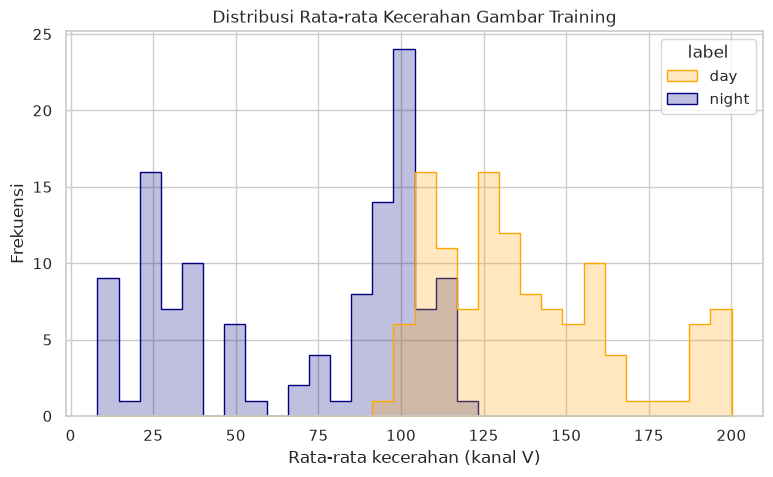

In [8]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=train_df,
    x="brightness",
    hue="label",
    bins=30,
    element="step",
    palette={"day": "orange", "night": "navy"},
)
plt.title("Distribusi Rata-rata Kecerahan Gambar Training")
plt.xlabel("Rata-rata kecerahan (kanal V)")
plt.ylabel("Frekuensi")
plt.show()

Distribusi menunjukkan bahwa gambar siang cenderung memiliki kecerahan lebih tinggi daripada gambar malam. Namun, masih ada tumpang tindih di sekitar nilai 80–120, sehingga threshold tunggal tidak akan sempurna.

### 5. Klasifikasi dengan threshold

Aturan prediksi:

$$
\hat{y} =
\begin{cases}
1 \text{ (day)}, & \text{jika brightness} > \text{threshold} \\
0 \text{ (night)}, & \text{selain itu}
\end{cases}
$$

Kita gunakan threshold **120** seperti pada modul.

In [9]:
def evaluate_threshold(df, threshold):
    pred = (df["brightness"] > threshold).astype(int)
    acc = accuracy_score(df["label_num"], pred)
    cm = confusion_matrix(df["label_num"], pred, labels=[0, 1])
    return acc, cm


acc_train_120, cm_train_120 = evaluate_threshold(train_df, 120)
acc_test_120, cm_test_120 = evaluate_threshold(test_df, 120)

print(f"Akurasi training (threshold=120): {acc_train_120:.4f}")
print(f"Akurasi test     (threshold=120): {acc_test_120:.4f}")
print("\nConfusion matrix training:")
print(cm_train_120)
print("\nConfusion matrix test:")
print(cm_test_120)

Akurasi training (threshold=120): 0.8417
Akurasi test     (threshold=120): 0.8688

Confusion matrix training:
[[120   0]
 [ 38  82]]

Confusion matrix test:
[[78  2]
 [19 61]]


### 6. Mencari threshold yang lebih baik

Threshold 120 bukan satu-satunya pilihan. Kita evaluasi threshold dari 0 sampai 255 pada data training, lalu memilih threshold dengan akurasi training tertinggi. Threshold tersebut kemudian diuji pada data test.

Threshold terbaik pada training: 100
Akurasi training: 0.9042
Akurasi test    : 0.9250


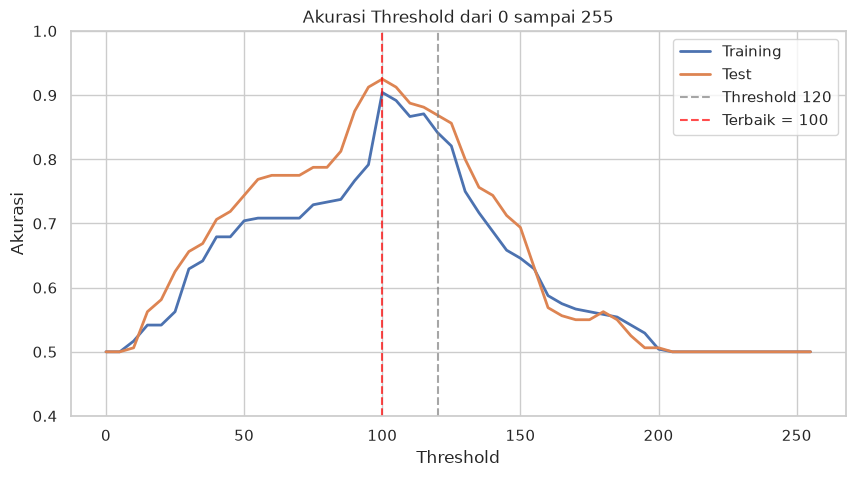

In [10]:
thresholds = np.arange(0, 256, 5)

acc_train_list = []
acc_test_list = []

for t in thresholds:
    acc_train_list.append(evaluate_threshold(train_df, t)[0])
    acc_test_list.append(evaluate_threshold(test_df, t)[0])

best_idx = int(np.argmax(acc_train_list))
best_threshold = int(thresholds[best_idx])

print("Threshold terbaik pada training:", best_threshold)
print(f"Akurasi training: {acc_train_list[best_idx]:.4f}")
print(f"Akurasi test    : {acc_test_list[best_idx]:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(thresholds, acc_train_list, label="Training", linewidth=2)
plt.plot(thresholds, acc_test_list, label="Test", linewidth=2)
plt.axvline(120, color="gray", linestyle="--", alpha=0.7, label="Threshold 120")
plt.axvline(best_threshold, color="red", linestyle="--", alpha=0.7, label=f"Terbaik = {best_threshold}")
plt.title("Akurasi Threshold dari 0 sampai 255")
plt.xlabel("Threshold")
plt.ylabel("Akurasi")
plt.ylim(0.4, 1.0)
plt.legend()
plt.show()

### 7. Klasifikasi dengan SVM kernel RBF

SVM RBF menggunakan fitur kecerahan yang sama. Berbeda dengan threshold, SVM mempelajari batas keputusan dari data, meskipun dengan satu fitur SVM RBF pada dasarnya juga membentuk batas berbasis ambang.

In [11]:
X_train = train_df[["brightness"]].values
y_train = train_df["label_num"].values
X_test = test_df[["brightness"]].values
y_test = test_df["label_num"].values

model_svm = SVC(kernel="rbf")
model_svm.fit(X_train, y_train)

y_train_pred = model_svm.predict(X_train)
y_test_pred = model_svm.predict(X_test)

acc_train_svm = accuracy_score(y_train, y_train_pred)
acc_test_svm = accuracy_score(y_test, y_test_pred)

print(f"Akurasi training SVM: {acc_train_svm:.4f}")
print(f"Akurasi test SVM    : {acc_test_svm:.4f}")
print("\nConfusion matrix test:")
print(confusion_matrix(y_test, y_test_pred))

Akurasi training SVM: 0.8583
Akurasi test SVM    : 0.9000

Confusion matrix test:
[[74  6]
 [10 70]]


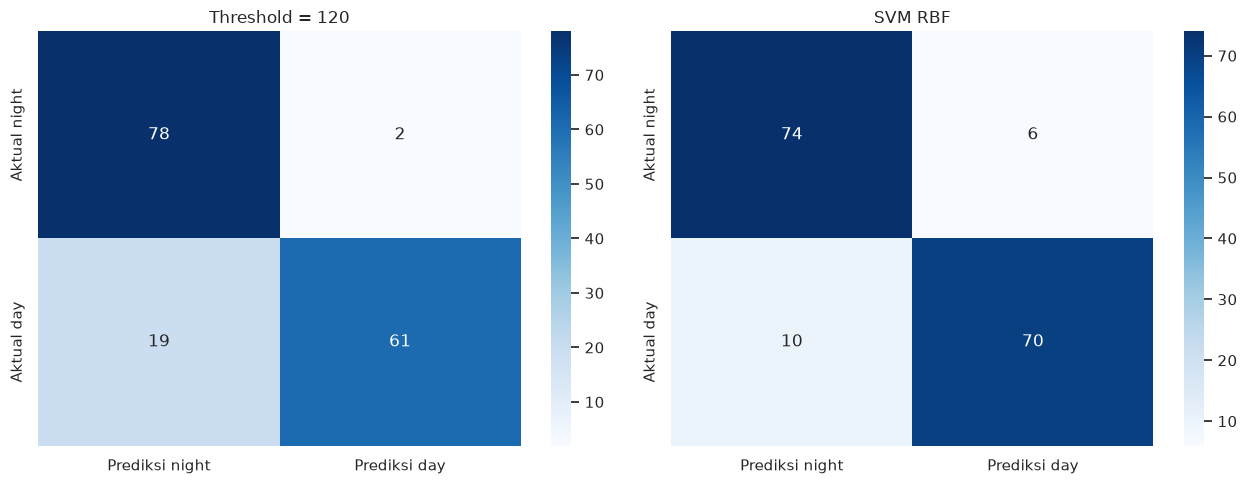

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, cm, title in [
    (axes[0], cm_test_120, "Threshold = 120"),
    (axes[1], confusion_matrix(y_test, y_test_pred), "SVM RBF"),
]:
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Prediksi night", "Prediksi day"],
        yticklabels=["Aktual night", "Aktual day"],
        ax=ax,
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

### 8. Perbandingan hasil

In [13]:
perbandingan = pd.DataFrame({
    "Metode": [
        "Threshold 120",
        f"Threshold {best_threshold} (hasil tuning)",
        "SVM RBF (brightness)",
    ],
    "Akurasi training": [acc_train_120, acc_train_list[best_idx], acc_train_svm],
    "Akurasi test": [acc_test_120, acc_test_list[best_idx], acc_test_svm],
})
perbandingan.round(4)

,Metode,Akurasi training,Akurasi test
0,Threshold 120,0.8417,0.8688
1,Threshold 100 (hasil tuning),0.9042,0.9250
2,SVM RBF (brightness),0.8583,0.9000


### 9. Interpretasi dan kesimpulan

**Hasil**

- Threshold 120: akurasi training **0,8417**, test **0,8688**.
- Threshold terbaik pada training (dengan langkah 5) adalah **100**: akurasi training **0,9042**, test **0,9250**.
- SVM RBF dengan fitur kecerahan: akurasi training **0,8583**, test **0,9000**.

**Analisis**

- Gambar siang dan malam dapat dibedakan cukup baik hanya dengan rata-rata kecerahan.
- Threshold 120 tidak optimal. Dengan menggeser threshold ke 100, akurasi test meningkat dari 86,88% menjadi 92,50%.
- SVM RBF dengan satu fitur kecerahan mencapai 90,00% pada test, lebih baik daripada threshold 120 tetapi masih di bawah threshold yang dituning.
- Threshold yang dituning pada training tetap bekerja lebih baik pada test, menunjukkan bahwa hubungan kecerahan–label cukup stabil.
- Namun, fitur rata-rata kecerahan saja memiliki keterbatasan: gambar senja, lampu jalan, atau langit mendung dapat memiliki kecerahan yang mirip.

**Keterbatasan**

- Threshold sangat bergantung pada dataset dan kondisi pencahayaan.
- Rata-rata kecerahan menghilangkan informasi spasial dan distribusi warna.
- Data test berasal dari distribusi yang sama dengan training; performa pada lokasi/kamera lain bisa berbeda.
- SVM dengan satu fitur tidak banyak berbeda dari classifier threshold; diperlukan fitur yang lebih kaya, misalnya histogram.

**Kesimpulan**

1. Rata-rata kecerahan HSV adalah fitur sederhana yang cukup efektif untuk klasifikasi siang/malam.
2. Threshold perlu dituning; threshold 100 memberi akurasi test lebih baik daripada 120.
3. SVM RBF mencapai akurasi test **90,00%** dengan satu fitur.
4. Untuk peningkatan lebih lanjut, fitur histogram kecerahan atau warna dapat digunakan, seperti pada bagian Tugas Praktikum.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS11 – Klasifikasi 2, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2
- Modul Praktikum Pembelajaran Mesin JS15 – Klasifikasi Gambar Day vs Night.
- OpenCV – Color conversions. https://docs.opencv.org/4.x/de/d25/imgproc_color_conversions.html
- `scikit-learn` – SVC. https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html